# Encontro 6 — Autômatos celulares

**Modelagem Dinâmica Espacial · PPGC&TAmb/UFMA**

No encontro 5 cada modelo era um único lugar. Agora o espaço entra: uma grade de células, cada uma com um **estado**, que muda a cada passo conforme o estado das **vizinhas**. É a base dos modelos de mudança de uso da terra que veremos a partir do encontro 8.

Um autômato celular tem quatro ingredientes:

| Ingrediente | Pergunta |
|---|---|
| Espaço celular | Que células existem? |
| Estado | Que valor cada célula guarda? |
| Vizinhança | Quem influencia cada célula? |
| Regra | Como o estado muda a cada passo? |

Rode as células na ordem. 🔧 = troque um número e rode de novo; ✏️ = responda.

## 0. Preparação

In [1]:
# !pip install -q "dissmodel==0.6.6" "dissmodel-ca @ git+https://github.com/DisSModel/dissmodel-ca.git@v0.2.0"
import contextlib, io, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from dissmodel.core import Environment, Model
from dissmodel.geo import vector_grid, parse_idx
from dissmodel.geo.raster.backend import RasterBackend, DIRS_MOORE, DIRS_VON_NEUMANN
from dissmodel_ca.models import GameOfLife, GameOfLifeRaster, FireModelRaster, FireState, PATTERNS
from dissmodel_ca.models._neighborhood import grid_neighbors

Duas funções de apoio: uma roda um modelo guardando "fotos" da grade em alguns passos; a outra desenha essas fotos. Só use.

In [2]:
def rodar(criar_modelo, ler_grade, passos, fotos):
    """Roda até `passos`, guardando a grade (via `ler_grade`) nos passos de `fotos`."""
    env = Environment(start_time=1, end_time=passos)
    criar_modelo()
    album = {0: ler_grade()}

    class Fotografo(Model):             # roda depois do modelo, a cada passo
        def execute(self):
            t = int(self.env.now())
            if t in fotos:
                album[t] = ler_grade()

    Fotografo()
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return album


def mostrar(album, cores=("white", "black"), vmax=1, tamanho=2.6):
    fig, eixos = plt.subplots(1, len(album), figsize=(tamanho * len(album), tamanho))
    for ax, (t, grade) in zip(np.atleast_1d(eixos), album.items()):
        ax.imshow(grade, cmap=ListedColormap(cores), vmin=0, vmax=vmax, origin="lower")   # linha 0 embaixo, como no mapa
        ax.set_title(t if isinstance(t, str) else f"passo {t}"); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()


def como_matriz(gdf, coluna="state"):
    """Converte a grade vetorial (uma linha por célula) numa matriz linha × coluna."""
    pos = [parse_idx(i) for i in gdf.index]
    m = np.zeros((max(p.row for p in pos) + 1, max(p.col for p in pos) + 1), dtype=int)
    for p, v in zip(pos, gdf[coluna]):
        m[p.row, p.col] = v
    return m

## 1. O espaço celular

No DisSModel, uma grade vetorial é uma tabela do GeoPandas: **uma linha por célula**, com a geometria (um quadrado) e os atributos. O identificador de cada célula é `"linha-coluna"`.

In [3]:
grade = vector_grid(dimension=(5, 5), resolution=1, attrs={"state": 0})
grade.head()

,geometry,state
id,,
0-0,"POLYGON ((1 0, 1 1, 0 1, 0 0, 1 0))",0
1-0,"POLYGON ((1 1, 1 2, 0 2, 0 1, 1 1))",0
2-0,"POLYGON ((1 2, 1 3, 0 3, 0 2, 1 2))",0
3-0,"POLYGON ((1 3, 1 4, 0 4, 0 3, 1 3))",0
4-0,"POLYGON ((1 4, 1 5, 0 5, 0 4, 1 4))",0


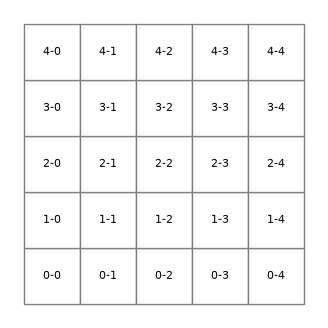

In [4]:
ax = grade.plot(facecolor="white", edgecolor="gray", figsize=(4, 4))
for idx, centro in zip(grade.index, grade.geometry.centroid):
    ax.annotate(idx, (centro.x, centro.y), ha="center", va="center", fontsize=8)
ax.set_axis_off()

## 2. A vizinhança

As duas vizinhanças clássicas:

- **von Neumann**: as 4 células que tocam por um lado;
- **Moore**: as 8 células em volta, incluindo as diagonais.

E uma decisão que quase sempre passa despercebida: o que acontece **na borda**? A grade pode ser **fechada** (a borda é o fim do mundo) ou **periódica** (o que sai por um lado entra pelo outro, como um toro). O TerraME usa a periódica em vários exemplos (`wrap = true`).

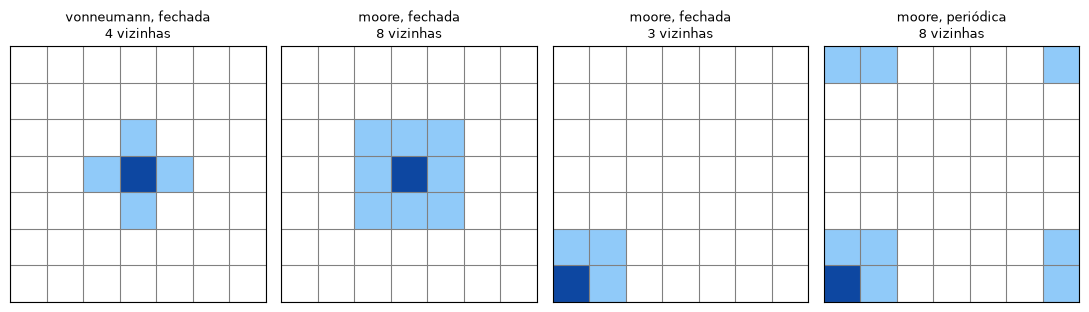

In [5]:
def desenhar_vizinhos(ax, celula, estrategia, periodica, n=7):
    viz = grid_neighbors(vector_grid(dimension=(n, n), resolution=1).index, estrategia, wrap=periodica)[celula]
    m = np.zeros((n, n))
    for v in viz:
        p = parse_idx(v); m[p.row, p.col] = 1
    p = parse_idx(celula); m[p.row, p.col] = 2
    ax.imshow(m, cmap=ListedColormap(["white", "#90caf9", "#0d47a1"]), vmin=0, vmax=2, origin="lower")
    ax.set_xticks(np.arange(-.5, n), minor=True); ax.set_yticks(np.arange(-.5, n), minor=True)
    ax.grid(which="minor", color="gray"); ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    ax.set_title(f"{estrategia}, {'periódica' if periodica else 'fechada'}\n{len(viz)} vizinhas", fontsize=9)

fig, eixos = plt.subplots(1, 4, figsize=(11, 3))
desenhar_vizinhos(eixos[0], "3-3", "vonneumann", False)
desenhar_vizinhos(eixos[1], "3-3", "moore", False)
desenhar_vizinhos(eixos[2], "0-0", "moore", False)
desenhar_vizinhos(eixos[3], "0-0", "moore", True)
plt.tight_layout()

✏️ **Pergunta 1.** Num modelo de desmatamento sobre o estado do Maranhão, faz sentido uma borda periódica? Que borda você usaria, e o que deveria acontecer com as células da divisa com o Pará?

## 3. A regra: o Jogo da Vida

O Jogo da Vida (Conway, 1970) tem só duas regras, aplicadas a todas as células ao mesmo tempo, com vizinhança de Moore:

- uma célula **viva** continua viva se tiver 2 ou 3 vizinhas vivas; senão, morre;
- uma célula **morta** nasce se tiver exatamente 3 vizinhas vivas.

Começamos com o **planador** (*glider*), cinco células que se deslocam pela grade.

In [6]:
print(np.array(PATTERNS["glider"]))

[[0 1 0]
 [0 0 1]
 [1 1 1]]


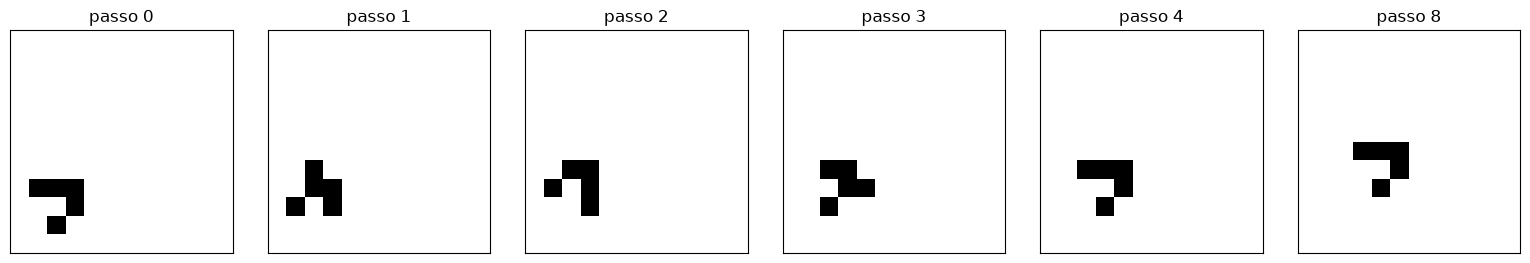

In [7]:
N = 12

def planador_vetorial(periodica):
    g = vector_grid(dimension=(N, N), resolution=1, attrs={"state": 0})
    for i, linha in enumerate(PATTERNS["glider"]):
        for j, v in enumerate(linha):
            g.loc[f"{1 + i}-{1 + j}", "state"] = v
    return GameOfLife(gdf=g, wrap=periodica)

modelo = {}
album = rodar(lambda: modelo.update(m=planador_vetorial(True)),
              lambda: como_matriz(modelo["m"].gdf), passos=8, fotos={1, 2, 3, 4, 8})
mostrar(album)

A cada 4 passos o planador volta à mesma forma, deslocado uma célula na diagonal. Nada no código diz "ande na diagonal": o movimento **emerge** da regra local.

🔧 **Borda periódica × fechada.** Com 40 passos o planador chega à borda. Rode as duas versões.

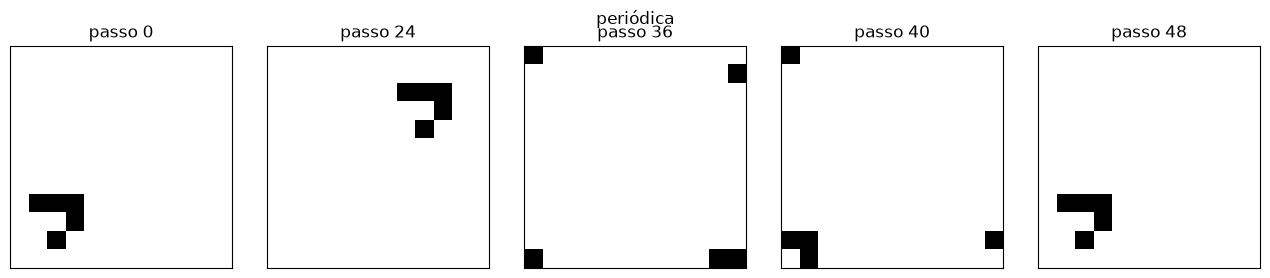

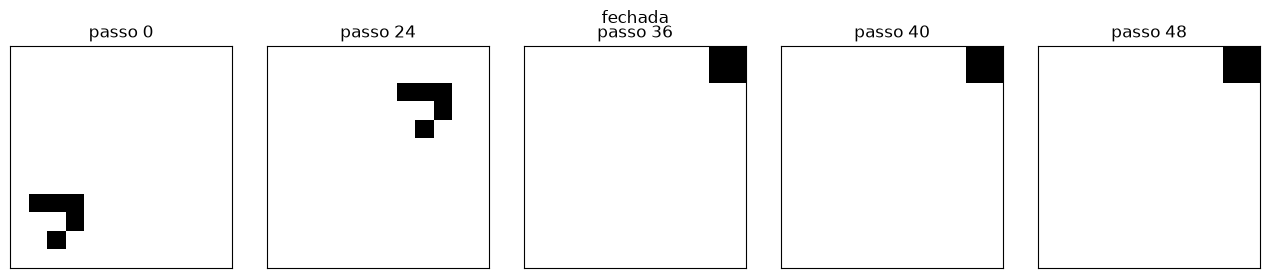

In [8]:
for periodica in (True, False):
    album = rodar(lambda: modelo.update(m=planador_vetorial(periodica)),
                  lambda: como_matriz(modelo["m"].gdf), passos=48, fotos={24, 36, 40, 48})
    mostrar(album)
    plt.suptitle("periódica" if periodica else "fechada", y=1.05)

✏️ **Pergunta 2.** O que aconteceu com o planador na grade fechada? A regra foi a mesma nas duas rodadas; o que mudou?

## 4. O mesmo modelo, outro substrato: raster

A grade vetorial é ótima para dados reais (municípios, polígonos irregulares), mas cada célula é tratada uma a uma. O DisSModel tem a mesma regra escrita sobre **matrizes** (raster): a grade inteira é atualizada de uma vez.

In [9]:
def cronometrar(criar, passos=20):
    env = Environment(start_time=1, end_time=passos)
    criar()
    t = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return (time.perf_counter() - t) / passos

n = 30
vetor = cronometrar(lambda: GameOfLife(gdf=vector_grid(dimension=(n, n), resolution=1, attrs={"state": 0})))

def raster_vazio():
    b = RasterBackend(shape=(n, n)); b.set("state", np.zeros((n, n), dtype=np.int8))
    return GameOfLifeRaster(backend=b)
raster = cronometrar(raster_vazio)

print(f"grade {n}×{n}, segundos por passo:  vetor {vetor:.3f}   raster {raster:.5f}   (raster ≈ {vetor / raster:.0f}× mais rápido)")

grade 30×30, segundos por passo:  vetor 0.218   raster 0.00009   (raster ≈ 2341× mais rápido)


Com a velocidade do raster, uma grade de 200 × 200 (40 mil células), começando aleatória, roda 200 passos em segundos:

células vivas no passo 200: 2576


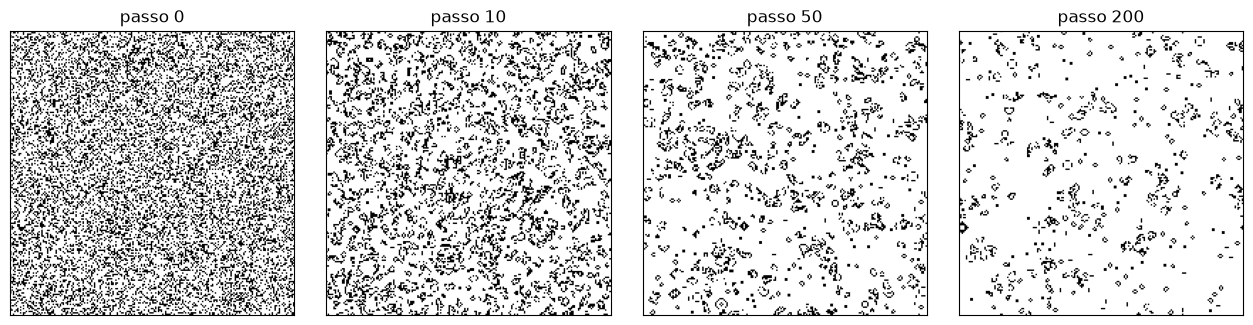

In [10]:
n = 200
rng = np.random.default_rng(1)
b = RasterBackend(shape=(n, n))
b.set("state", (rng.random((n, n)) < 0.3).astype(np.int8))
album = rodar(lambda: GameOfLifeRaster(backend=b), lambda: b.arrays["state"].copy(),
              passos=200, fotos={10, 50, 200})
mostrar(album, tamanho=3.2)
print("células vivas no passo 200:", int(album[200].sum()))

## 5. É o mesmo Jogo da Vida do TerraME?

O `terrame-goldens` guarda a grade inteira, passo a passo, de rodadas do TerraME. Pegamos o caso do planador (30 × 30, 100 passos), começamos do mesmo estado inicial e comparamos **célula a célula em todos os passos**.

In [11]:
URL = "https://raw.githubusercontent.com/LambdaGeo/terrame-goldens/v0.1.0/goldens/ca/grids/{}.csv.gz"
ref = pd.read_csv(URL.format("life_glider"))
colunas = [c for c in ref.columns if c.startswith("x")]
terrame = {t: (g.sort_values("y")[colunas].to_numpy() == "alive").astype(int)
           for t, g in ref.groupby("step")}
print("passos guardados:", len(terrame), " grade:", terrame[0].shape)

passos guardados: 101  grade: (30, 30)


células diferentes, somando todos os passos: 0


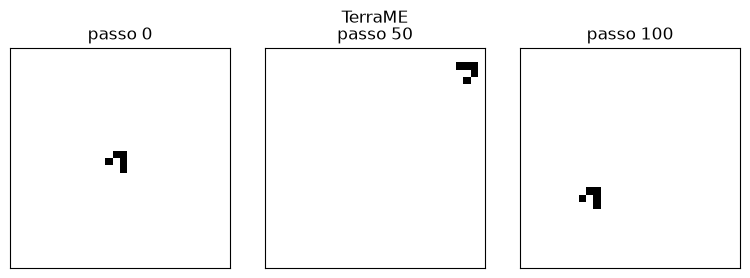

In [12]:
b = RasterBackend(shape=terrame[0].shape)
b.set("state", terrame[0].astype(np.int8))
nosso = rodar(lambda: GameOfLifeRaster(backend=b), lambda: b.arrays["state"].astype(int).copy(),
              passos=100, fotos=set(range(1, 101)))

diferentes = {t: int((nosso[t] != terrame[t]).sum()) for t in terrame}
print("células diferentes, somando todos os passos:", sum(diferentes.values()))
mostrar({t: terrame[t] for t in (0, 50, 100)})
plt.suptitle("TerraME", y=1.05);

Zero células diferentes em 100 passos. Mas atenção: isso só é possível porque o Jogo da Vida é **determinístico**. Modelos com sorteio a cada passo (como o incêndio da próxima seção, no TerraME) não podem ser comparados célula a célula, porque o TerraME e o Python sorteiam números diferentes. Para eles, compara-se a **distribuição** de muitas rodadas (encontro 13).

## 6. Um processo espacial: incêndio e conectividade da floresta

Voltamos ao incêndio do encontro 4, agora como pergunta de paisagem. Cada célula é floresta com probabilidade *p* (senão, vazia); o fogo começa em toda a borda esquerda e passa para a floresta vizinha (von Neumann). Quanto da floresta queima?

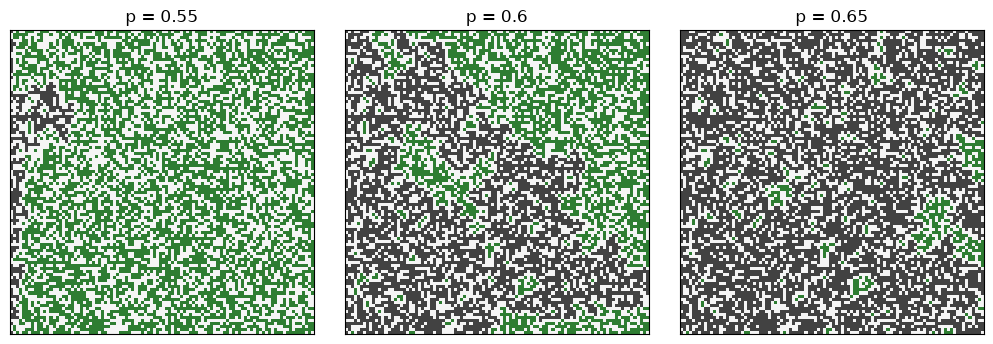

In [13]:
def incendio(p, semente, n=100, vizinhanca=DIRS_VON_NEUMANN):
    rng = np.random.default_rng(semente)
    s = np.where(rng.random((n, n)) < p, FireState.FOREST, FireState.EMPTY).astype(np.int8)
    s[:, 0] = np.where(s[:, 0] == FireState.FOREST, FireState.BURNING, s[:, 0])   # acende a borda esquerda
    floresta = int((s != FireState.EMPTY).sum())
    b = RasterBackend(shape=(n, n)); b.set("state", s)

    def criar():
        modelo = FireModelRaster(backend=b)
        modelo.dirs = vizinhanca                 # von Neumann (4) por padrão, como no TerraME
    rodar(criar, lambda: None, passos=4 * n, fotos=set())
    final = b.arrays["state"]
    return final, (final == FireState.BURNED).sum() / floresta

cores_fogo = ("#2e7d32", "#e65100", "#424242", "#f5f5f5")   # floresta, queimando, queimada, vazia
mostrar({f"p = {p}": incendio(p, semente=1)[0] for p in (0.55, 0.60, 0.65)}, cores=cores_fogo, vmax=3, tamanho=3.4)

Uma diferença pequena na cobertura florestal muda tudo. Vamos medir com várias densidades e 10 sementes cada (cerca de 3 s):

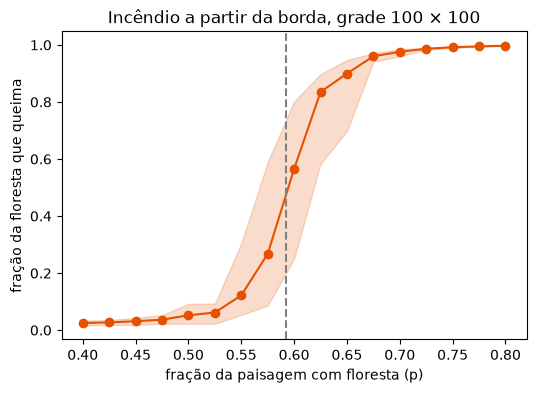

In [14]:
linhas = []
for p in np.arange(0.40, 0.81, 0.025):
    for semente in range(10):
        linhas.append({"p": round(p, 3), "semente": semente, "queimada": incendio(p, semente)[1]})
curva = pd.DataFrame(linhas).groupby("p")["queimada"].agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curva.index, curva["mean"], "o-", color="#e65100")
ax.fill_between(curva.index, curva["min"], curva["max"], color="#e65100", alpha=0.2)
ax.axvline(0.5927, color="gray", linestyle="--")
ax.set(xlabel="fração da paisagem com floresta (p)", ylabel="fração da floresta que queima",
       title="Incêndio a partir da borda, grade 100 × 100");

Abaixo de cerca de 0,59 a floresta está em **fragmentos** desconectados e o fogo para cedo; acima, há um caminho de floresta contínuo de lado a lado e quase tudo queima. Esse limiar de **percolação** (cerca de 0,5927 para esta vizinhança, valor estimado numericamente) não está escrito em lugar nenhum do código: emerge da regra local e da estrutura do espaço.

✏️ **Pergunta 3.** O mesmo raciocínio vale para uma espécie que se dispersa pela floresta, ou para o desmatamento que avança a partir de estradas. Que pergunta de pesquisa da sua área poderia ser feita com um modelo assim?

✏️ **Pergunta 4.** A faixa sombreada mostra a variação entre as 10 sementes. Onde ela é mais larga, e por quê? O que isso diz sobre usar uma só rodada de um modelo com sorteio?

## Para casa

1. Refaça a curva com vizinhança de Moore (8 vizinhas): na célula da curva, troque `incendio(p, semente)` por `incendio(p, semente, vizinhanca=DIRS_MOORE)`. O limiar sobe ou desce? Por quê?
2. No Jogo da Vida em raster, comece com 10%, 30% e 50% de células vivas. Quantas sobram no passo 200? Faça uma tabela.
3. Traga uma frase: num modelo de uso da terra da sua área, qual seria o estado de cada célula, e quem seriam as vizinhas que importam?